# 02 — Text Preprocessing & Feature Extraction

> **Purpose** — Transform raw CTI text into a clean, numeric representation suitable for machine learning and topic modeling. This produces the artifacts consumed by all downstream notebooks.

<span class="badge badge-blue">NLP</span><span class="badge badge-green">Cleaning</span><span class="badge badge-orange">TF-IDF</span>

## Table of Contents

1. [Setup & Imports](#1-setup--imports)
2. [Load Raw Dataset](#2-load-raw-dataset)
3. [Inspect Raw Text Samples](#3-inspect-raw-text-samples)
4. [Text Cleaning Function](#4-text-cleaning-function)
5. [Apply Preprocessing](#5-apply-preprocessing)
6. [Before / After Comparison](#6-before--after-comparison)
7. [Duplicate Removal](#7-duplicate-removal)
8. [Token & Vocabulary Statistics](#8-token--vocabulary-statistics)
9. [Temporal Parsing](#9-temporal-parsing)
10. [TF-IDF Feature Extraction](#10-tf-idf-feature-extraction)
11. [Save Cleaned Dataset & Vectorizer](#11-save-cleaned-dataset--vectorizer)
12. [Summary](#12-summary)


## 1. Setup & Imports

In [1]:
import sys, pathlib, re
sys.path.append(str(pathlib.Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from collections import Counter

from src.config import DATASET_FILE, OUTPUT_DIR, MODELS_DIR, FIGURES_DIR
from src.preprocess import clean_text
from src.features import build_tfidf

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print('Raw dataset :', DATASET_FILE)
print('Output dir  :', OUTPUT_DIR)
print('Models dir  :', MODELS_DIR)

Raw dataset : D:\Projects\done\thesis\Implementation\dataset\synthetic_cti_reports.csv
Output dir  : D:\Projects\done\thesis\Implementation\output
Models dir  : D:\Projects\done\thesis\Implementation\output\models


## 2. Load Raw Dataset

In [2]:
df = pd.read_csv(DATASET_FILE)
print('Loaded rows:', len(df))
print('Columns     :', list(df.columns))
df.head(3)

Loaded rows: 10000
Columns     : ['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators']


,id,title,text,category,date,source,url,severity,threat_actor,malware,attack_vector,target_sector,country,cve_id,mitre_technique,mitre_technique_name,indicators
0,3568,DDoS activity targeting Retail organizations,A recent threat campaign involved ddos activit...,DDoS,2021-01-01,CTI-Source-6,https://cti-reports.example.org/report/3568,High,BlackOrchid,SilverWorm,Drive-by Download,Retail,Japan,CVE-2022-39414,T1059,Command and Scripting Interpreter,IP=111.96.63.206; DOMAIN=wall-west.net; SHA256...
1,5617,Web Attack activity targeting Financial Servic...,A medium web attack campaign targeted organiza...,Web Attack,2021-01-01,CTI-Source-9,https://cti-reports.example.org/report/5617,Medium,DarkHydra,DarkLoader,Brute Force,Financial Services,United States,CVE-2024-29220,T1053,Scheduled Task/Job,IP=150.80.211.45; DOMAIN=austin-moreno.net; SH...
2,2016,Credential Theft activity targeting Retail org...,A high credential theft campaign targeted orga...,Credential Theft,2021-01-01,CTI-Source-11,https://cti-reports.example.org/report/2016,High,StormByte,SilverWorm,Exposed Service,Retail,Australia,CVE-2026-54394,T1566.001,Spearphishing Attachment,IP=143.178.240.66; DOMAIN=briggs.org; SHA256=f...


## 3. Inspect Raw Text Samples

Sample raw documents per category to understand vocabulary and noise.

In [3]:
for cat in df['category'].unique():
    sample = df[df['category'] == cat]['text'].iloc[0]
    print(f'\n--- {cat} ---')
    print(sample[:250])


--- DDoS ---
A recent threat campaign involved ddos activity against the Retail sector. Initial access was linked to drive-by download. Analysts observed distributed denial of service and additional activity associated with SilverWorm. The campaign affected syste

--- Web Attack ---
A medium web attack campaign targeted organizations in the Financial Services sector located in United States. The activity was associated with DarkHydra and involved brute force. Security analysts observed web shell activity and identified the use o

--- Credential Theft ---
A high credential theft campaign targeted organizations in the Retail sector located in Australia. The activity was associated with StormByte and involved exposed service. Security analysts observed session token activity and identified the use of Si

--- Phishing ---
A high phishing campaign targeted organizations in the Banking sector located in India. The activity was associated with APT-Alpha and involved brute force. Security ana

<div class="callout"><b>Observation:</b> Raw text contains mixed casing, punctuation, URLs, IP addresses, hashes, and CTI-specific tokens that must be handled carefully.</div>

## 4. Text Cleaning Function

The `clean_text()` function applies:
- Lowercase normalization
- HTML tag stripping
- Non-alphanumeric removal (preserves `.`, `-`, `/`, `:`, `_` for IoCs)
- Whitespace normalization
- Stop-word removal
- Lemmatization

In [4]:
sample = df['text'].iloc[0]
print('RAW:')
print(sample[:300])
print()
cleaned = clean_text(sample)
print('CLEANED:')
print(cleaned[:300])

RAW:
A recent threat campaign involved ddos activity against the Retail sector. Initial access was linked to drive-by download. Analysts observed distributed denial of service and additional activity associated with SilverWorm. The campaign affected systems in Japan and was classified as high severity. T

CLEANED:
recent threat campaign involved ddos activity against retail sector. initial access linked drive-by download. analyst observed distributed denial service additional activity associated with silverworm. campaign affected system japan classified high severity. observed vulnerability identifier cve-202


## 5. Apply Preprocessing

In [5]:
df['clean_text'] = df['text'].astype(str).apply(clean_text)
df['orig_len']   = df['text'].astype(str).str.len()
df['clean_len']  = df['clean_text'].str.len()
df['orig_words'] = df['text'].astype(str).str.split().str.len()
df['clean_words']= df['clean_text'].str.split().str.len()

print('Preprocessing complete.')
print(df[['orig_words','clean_words']].describe().round(1))

Preprocessing complete.
       orig_words  clean_words
count     10000.0      10000.0
mean         59.9         47.5
std           3.2          2.4
min          55.0         44.0
25%          58.0         46.0
50%          59.0         47.0
75%          61.0         49.0
max          70.0         57.0


In [6]:
empty = (df['clean_text'].str.strip() == '').sum()
print(f'Empty after cleaning: {empty}')
if empty > 0:
    print('Removing empty rows...')
    df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
    print(f'Rows remaining: {len(df)}')

Empty after cleaning: 0


## 6. Before / After Comparison

In [7]:
compare = pd.DataFrame({
    'original': df['text'].head(3).str.slice(0, 120),
    'cleaned' : df['clean_text'].head(3).str.slice(0, 120),
})
pd.set_option('display.max_colwidth', None)
compare

,original,cleaned
0,A recent threat campaign involved ddos activity against the Retail sector. Initial access was linked to drive-by downloa,recent threat campaign involved ddos activity against retail sector. initial access linked drive-by download. analyst ob
1,A medium web attack campaign targeted organizations in the Financial Services sector located in United States. The activ,medium web attack campaign targeted organization financial service sector located united states. activity associated wit
2,A high credential theft campaign targeted organizations in the Retail sector located in Australia. The activity was asso,high credential theft campaign targeted organization retail sector located australia. activity associated with stormbyte


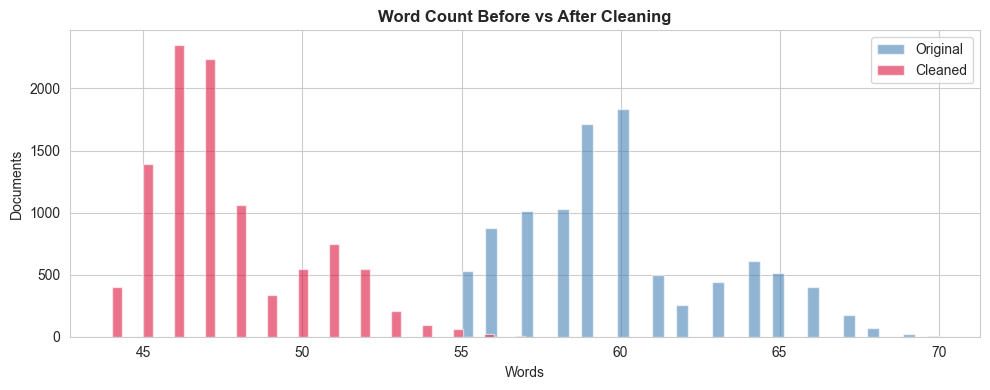

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df['orig_words'],  bins=40, alpha=0.6, label='Original', color='steelblue')
ax.hist(df['clean_words'], bins=40, alpha=0.6, label='Cleaned',  color='crimson')
ax.set_title('Word Count Before vs After Cleaning', fontweight='bold')
ax.set_xlabel('Words')
ax.set_ylabel('Documents')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_wordcount_comparison.png')
plt.show()

## 7. Duplicate Removal

In [9]:
before = len(df)
df = df.drop_duplicates(subset=['clean_text']).reset_index(drop=True)
removed = before - len(df)
print(f'Rows before  : {before}')
print(f'Duplicates   : {removed}')
print(f'Rows after   : {len(df)}')

Rows before  : 10000
Duplicates   : 0
Rows after   : 10000


## 8. Token & Vocabulary Statistics

In [10]:
all_tokens = ' '.join(df['clean_text']).split()
vocab      = Counter(all_tokens)

n_tokens = len(all_tokens)
n_unique = len(vocab)

print(f'Total tokens      : {n_tokens:,}')
print(f'Unique vocabulary : {n_unique:,}')
print(f'Avg tokens/doc    : {n_tokens / len(df):.1f}')
print()
print('Top 20 terms:')
for term, cnt in vocab.most_common(20):
    print(f'  {term:20s} {cnt}')

Total tokens      : 475,430
Unique vocabulary : 10,219
Avg tokens/doc    : 47.5

Top 20 terms:
  observed             20000
  activity             17459
  during               12541
  investigation.       12541
  additional           12468
  included             12463
  vulnerability        11138
  file                 10552
  network              10271
  campaign             10125
  identifier           10000
  indicator            10000
  address              10000
  domain               10000
  hash                 10000
  collected            10000
  threat               8542
  identified           7532
  access               5312
  security             5141


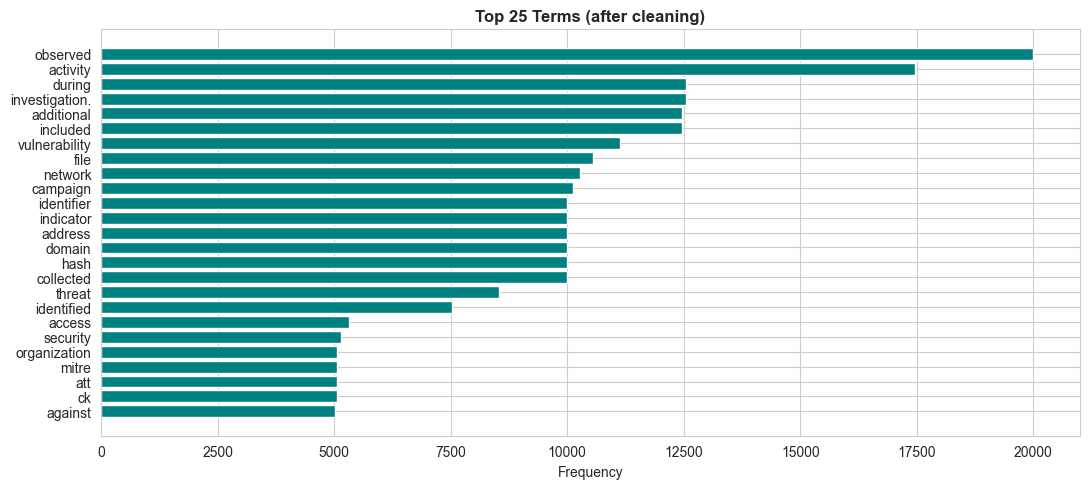

In [11]:
top = vocab.most_common(25)
terms, counts = zip(*top)

plt.figure(figsize=(11, 5))
plt.barh(range(len(terms)), counts, color='teal')
plt.yticks(range(len(terms)), terms)
plt.gca().invert_yaxis()
plt.title('Top 25 Terms (after cleaning)', fontweight='bold')
plt.xlabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_top_terms.png')
plt.show()

## 9. Temporal Parsing

Parse dates and derive a monthly `period` column. The `period` field is used later for temporal topic analysis and emerging-threat scoring.

In [12]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
invalid_dates = df['date'].isna().sum()
print(f'Invalid/missing dates: {invalid_dates}')

df = df.dropna(subset=['date']).reset_index(drop=True)
df['period'] = df['date'].dt.to_period('M').astype(str)

print('Date range :', df['date'].min().date(), '->', df['date'].max().date())
print('Periods    :', df['period'].nunique())
df[['date','period']].head()

Invalid/missing dates: 0
Date range : 2021-01-01 -> 2026-09-01
Periods    : 69


,date,period
0,2021-01-01,2021-01
1,2021-01-01,2021-01
2,2021-01-01,2021-01
3,2021-01-01,2021-01
4,2021-01-01,2021-01


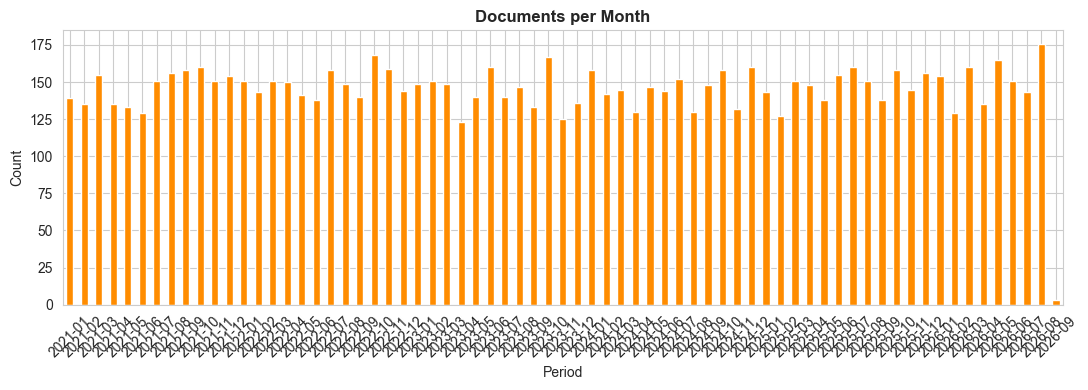

In [13]:
period_counts = df.groupby('period').size()

plt.figure(figsize=(11, 4))
period_counts.plot(kind='bar', color='darkorange', edgecolor='white')
plt.title('Documents per Month', fontweight='bold')
plt.xlabel('Period')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_period_counts.png')
plt.show()

## 10. TF-IDF Feature Extraction

Build the TF-IDF matrix using unigrams + bigrams. Configuration is read from `src/config.py`.

In [14]:
X, vectorizer = build_tfidf(df['clean_text'])

print('TF-IDF matrix shape :', X.shape)
print('Vocabulary size     :', len(vectorizer.vocabulary_))
print('N-gram range        :', vectorizer.ngram_range)
print('Max features        :', vectorizer.max_features)

TF-IDF matrix shape : (10000, 2356)
Vocabulary size     : 2356
N-gram range        : (1, 2)
Max features        : 10000


In [15]:
# Sparsity check
density = X.nnz / (X.shape[0] * X.shape[1])
print(f'Non-zero entries : {X.nnz:,}')
print(f'Density          : {density:.4%}')
print(f'Sparsity         : {1 - density:.4%}')

Non-zero entries : 626,338
Density          : 2.6585%
Sparsity         : 97.3415%


In [16]:
# Sample of most informative features (highest IDF-weighted terms)
feature_names = vectorizer.get_feature_names_out()
sample_feats = feature_names[::max(1, len(feature_names) // 30)]
print('Sample features (every Nth):')
print(', '.join(sample_feats[:30]))

Sample features (every Nth):
001, 15372, 2023 24548, 21789, 28864, 36233, 42431, 50111, 57968, 65410, 71621, 78260, 85399, 91866, account followed, authentication additional, ck t1059, data breach, drive by, file directory, identified credential, included employee, involved botnet, located singapore, nightwolf involved, organizations threat, redlinex activity, shell, t1053 observed, token while


<div class="callout"><b>Interpretation:</b> High sparsity (>99%) is expected for text. The SVM and Logistic Regression classifiers are well-suited to sparse high-dimensional feature spaces.</div>

## 11. Save Cleaned Dataset & Vectorizer

In [17]:
cleaned_path = OUTPUT_DIR / 'cleaned_cti.csv'
df.to_csv(cleaned_path, index=False)
print(f'Saved cleaned dataset  : {cleaned_path}')
print(f'  Rows: {len(df)}  Columns: {list(df.columns)}')

Saved cleaned dataset  : D:\Projects\done\thesis\Implementation\output\cleaned_cti.csv
  Rows: 10000  Columns: ['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators', 'clean_text', 'orig_len', 'clean_len', 'orig_words', 'clean_words', 'period']


In [18]:
vec_path = MODELS_DIR / 'tfidf_vectorizer.pkl'
joblib.dump(vectorizer, vec_path)
print(f'Saved TF-IDF vectorizer: {vec_path}')

Saved TF-IDF vectorizer: D:\Projects\done\thesis\Implementation\output\models\tfidf_vectorizer.pkl


In [19]:
# Sanity check - reload and verify
df_check = pd.read_csv(cleaned_path)
vec_check = joblib.load(vec_path)
print('Reload OK:')
print(f'  Rows        : {len(df_check)}')
print(f'  Columns     : {len(df_check.columns)}')
print(f'  Vocab size  : {len(vec_check.vocabulary_)}')

Reload OK:
  Rows        : 10000
  Columns     : 23
  Vocab size  : 2356


## 12. Summary

<div class="stat-grid"><div class="stat"><div class="value">N</div><div class="label">Documents</div></div><div class="stat"><div class="value">V</div><div class="label">Vocabulary</div></div><div class="stat"><div class="value">M</div><div class="label">Months</div></div><div class="stat"><div class="value">C</div><div class="label">Categories</div></div></div>

In [20]:
print('=== PREPROCESSING SUMMARY ===')
print(f'Documents         : {len(df):,}')
print(f'Vocabulary        : {len(vectorizer.vocabulary_):,}')
print(f'TF-IDF shape      : {X.shape}')
print(f'Months covered    : {df["period"].nunique()}')
print(f'Categories        : {df["category"].nunique()}')
print(f'Avg tokens/doc    : {df["clean_words"].mean():.1f}')
print()
print('Artifacts saved:')
print(f'  - {OUTPUT_DIR / "cleaned_cti.csv"}')
print(f'  - {MODELS_DIR / "tfidf_vectorizer.pkl"}')

=== PREPROCESSING SUMMARY ===
Documents         : 10,000
Vocabulary        : 2,356
TF-IDF shape      : (10000, 2356)
Months covered    : 69
Categories        : 10
Avg tokens/doc    : 47.5

Artifacts saved:
  - D:\Projects\done\thesis\Implementation\output\cleaned_cti.csv
  - D:\Projects\done\thesis\Implementation\output\models\tfidf_vectorizer.pkl


<div class="callout"><b>Next step:</b> Proceed to <code>03_classification.ipynb</code> to train classifiers on the cleaned dataset and TF-IDF features.</div>

---
*End of preprocessing notebook.*